# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** M. Khamim Ma'ruf

## Menentukan Pertanyaan Bisnis
1. Bagaimana pengaruh kondisi cuaca (`weathersit`) dan musim (`season`) terhadap rata-rata jumlah penyewaan sepeda harian (`cnt`) pada pengguna kasual (`casual`) dibandingkan pengguna terdaftar (`registered`) selama periode 2011–2012?
2. Pada rentang jam berapa (`hr`) terjadi lonjakan puncak penyewaan sepeda (`cnt`) antara hari kerja (`workingday`) dan akhir pekan/hari libur (`holiday`) sepanjang tahun 2011–2012, serta bagaimana proporsi tipe penggunanya?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gathering Data
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Preview day_df:")
display(day_df.head())
print("\nPreview hour_df:")
display(hour_df.head())

Preview day_df:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Preview hour_df:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("=== INFO DAY_DF ===")
day_df.info()
print("\nMissing values day_df:\n", day_df.isna().sum())
print("Duplikasi day_df:", day_df.duplicated().sum())
display(day_df.describe())

=== INFO DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing values day_df:
 instant       0
dteday        0
season        0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Insight Assessing Data (`day_df`):**
* **Kelengkapan & Duplikasi:** Dataset terdiri dari 731 baris dan 16 kolom dengan 0 *missing values* dan 0 data duplikat.
* **Tipe Data:** Kolom `dteday` masih bertipe `object` (string), sehingga perlu dikonversi menjadi `datetime`.
* **Inaccurate Value (Anomali Nilai):** Pada hasil `describe()`, nilai minimum kolom `hum` (kelembapan) adalah `0.0`, yang secara kondisi cuaca nyata merupakan nilai tidak wajar (kemungkinan kesalahan pencatatan sensor) dan dapat diganti dengan nilai median pada tahap *cleaning*.
* **Representasi Nilai & Penamaan Kolom:** Kolom kategorikal (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`) masih menggunakan kode angka integer dan beberapa nama kolom masih disingkat, sehingga perlu dilakukan *mapping* ke label yang deskriptif dan penyesuaian nama kolom.

In [5]:
print("\n=== INFO HOUR_DF ===")
hour_df.info()
print("\nMissing values hour_df:\n", hour_df.isna().sum())
print("Duplikasi hour_df:", hour_df.duplicated().sum())
display(hour_df.describe())


=== INFO HOUR_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Missing values hour_df:
 i

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Insight Assessing Data (`hour_df`):**
* **Kelengkapan & Duplikasi:** Dataset terdiri dari 17.379 baris dan 17 kolom dengan 0 *missing values* dan 0 data duplikat.
* **Tipe Data:** Kolom `dteday` masih bertipe `object` (string), sehingga perlu diubah menjadi `datetime`.
* **Inaccurate Value (Anomali Nilai):** Sama seperti pada `day_df`, nilai minimum kolom `hum` (kelembapan) adalah `0.0`, yang merupakan anomali pencatatan dan akan diganti dengan nilai median pada tahap *cleaning*.
* **Representasi Nilai & Penamaan Kolom:** Kolom kategorikal (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`) masih berupa kode angka integer dan menggunakan nama singkatan (termasuk `hr` untuk jam), sehingga perlu di-*mapping* ke label deskriptif dan disesuaikan penamaannya.

In [6]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Mengatasi inaccurate value pada kolom hum (nilai 0 diganti dengan median)
day_df['hum'] = day_df['hum'].replace(0, day_df['hum'].median())
hour_df['hum'] = hour_df['hum'].replace(0, hour_df['hum'].median())

# 3. Mengubah nama kolom agar lebih mudah dibaca
rename_cols = {
    'dteday': 'date',
    'yr': 'year',
    'mnth': 'month',
    'hr': 'hour',
    'weathersit': 'weather_condition',
    'hum': 'humidity',
    'cnt': 'total_count'
}
day_df.rename(columns=rename_cols, inplace=True)
hour_df.rename(columns=rename_cols, inplace=True)

# 4. Mapping nilai kategorikal agar deskriptif
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
year_map = {0: 2011, 1: 2012}
weather_map = {
    1: 'Clear / Partly Cloudy',
    2: 'Mist / Cloudy',
    3: 'Light Snow / Rain',
    4: 'Heavy Rain / Snow'
}
workingday_map = {0: 'Weekend / Holiday', 1: 'Working Day'}

for df in [day_df, hour_df]:
    df['season'] = df['season'].map(season_map)
    df['year'] = df['year'].map(year_map)
    df['weather_condition'] = df['weather_condition'].map(weather_map)
    df['workingday_label'] = df['workingday'].map(workingday_map)

# Mengecek hasil cleaning
print("Min humidity setelah cleaning (day_df):", day_df['humidity'].min())
print("Min humidity setelah cleaning (hour_df):", hour_df['humidity'].min())
display(day_df[['date', 'season', 'year', 'weather_condition', 'workingday_label', 'total_count']].head())
display(hour_df[['date', 'hour', 'season', 'weather_condition', 'total_count']].head())

Min humidity setelah cleaning (day_df): 0.187917
Min humidity setelah cleaning (hour_df): 0.08


,date,season,year,weather_condition,workingday_label,total_count
0,2011-01-01,Spring,2011,Mist / Cloudy,Weekend / Holiday,985
1,2011-01-02,Spring,2011,Mist / Cloudy,Weekend / Holiday,801
2,2011-01-03,Spring,2011,Clear / Partly Cloudy,Working Day,1349
3,2011-01-04,Spring,2011,Clear / Partly Cloudy,Working Day,1562
4,2011-01-05,Spring,2011,Clear / Partly Cloudy,Working Day,1600


,date,hour,season,weather_condition,total_count
0,2011-01-01,0,Spring,Clear / Partly Cloudy,16
1,2011-01-01,1,Spring,Clear / Partly Cloudy,40
2,2011-01-01,2,Spring,Clear / Partly Cloudy,32
3,2011-01-01,3,Spring,Clear / Partly Cloudy,13
4,2011-01-01,4,Spring,Clear / Partly Cloudy,1


**Insight Cleaning Data:**
* **Konversi Tipe Data:** Kolom `dteday` pada `day_df` maupun `hour_df` berhasil dikonversi dari `object` menjadi tipe `datetime` dan diubah namanya menjadi `date` agar siap digunakan untuk analisis deret waktu (*time-series*).
* **Penanganan Inaccurate Value:** Nilai anomali `0` pada kolom kelembapan (`humidity`) telah diganti dengan nilai mediannya, sehingga nilai minimum kelembapan berubah menjadi `0.187917` pada `day_df` dan `0.08` pada `hour_df` (lebih realistis secara meteorologi).
* **Standardisasi Nama & Label Kategorikal:** Nama-nama kolom yang disingkat telah diperjelas, dan seluruh kode angka kategorikal (`season`, `year`, `weather_condition`, serta `workingday_label`) berhasil diubah menjadi label teks yang deskriptif untuk mempermudah tahap eksplorasi dan visualisasi data.

## Exploratory Data Analysis (EDA)
### Eksplorasi Data untuk Pertanyaan 1: Pengaruh Musim dan Kondisi Cuaca

In [7]:
# Agregasi berdasarkan musim (season)
season_agg = day_df.groupby('season').agg({
    'casual': 'mean',
    'registered': 'mean',
    'total_count': ['mean', 'sum', 'count']
}).round(2)
print("=== Rata-rata & Total Penyewaan Berdasarkan Musim ===")
display(season_agg)

# Agregasi berdasarkan kondisi cuaca (weather_condition)
weather_agg = day_df.groupby('weather_condition').agg({
    'casual': 'mean',
    'registered': 'mean',
    'total_count': ['mean', 'sum', 'count']
}).round(2)
print("\n=== Rata-rata & Total Penyewaan Berdasarkan Kondisi Cuaca ===")
display(weather_agg)

=== Rata-rata & Total Penyewaan Berdasarkan Musim ===


casual registered total_count               
           mean       mean        mean      sum count
season                                               
Fall    1202.61    4441.69     5644.30  1061129   188
Spring   334.93    2269.20     2604.13   471348   181
Summer  1106.10    3886.23     4992.33   918589   184
Winter   729.11    3999.05     4728.16   841613   178


=== Rata-rata & Total Penyewaan Berdasarkan Kondisi Cuaca ===


casual registered total_count               
                         mean       mean        mean      sum count
weather_condition                                                  
Clear / Partly Cloudy  964.03    3912.76     4876.79  2257952   463
Light Snow / Rain      185.48    1617.81     1803.29    37869    21
Mist / Cloudy          687.35    3348.51     4035.86   996858   247

**Insight EDA Pertanyaan 1 (Pengaruh Musim & Cuaca):**
* **Berdasarkan Musim (`season`):** Musim gugur (**Fall**) mencatatkan rata-rata penyewaan harian tertinggi sebesar **5.644,30** sepeda/hari (total **1.061.129** penyewaan), disusul oleh **Summer** (**4.992,33**/hari) dan **Winter** (**4.728,16**/hari). Sebaliknya, **Spring** menjadi musim dengan penyewaan terendah (**2.604,13**/hari), dengan penurunan paling tajam terjadi pada pengguna kasual (rata-rata hanya **334,93**/hari dibandingkan **1.202,61**/hari pada musim gugur).
* **Berdasarkan Kondisi Cuaca (`weather_condition`):** Cuaca cerah/berawan sebagian (**Clear / Partly Cloudy**) mendominasi aktivitas penyewaan dengan rata-rata **4.876,79** sepeda/hari (total **2.257.952** penyewaan dalam 463 hari). Saat cuaca memburuk menjadi hujan ringan/salju ringan (**Light Snow / Rain**), rata-rata penyewaan harian anjlok drastis hingga **63%** menjadi hanya **1.803,29** sepeda/hari—terutama pengguna kasual yang turun tajam dari **964,03** menjadi **185,48**/hari.
* **Perilaku Pengguna:** Pengguna terdaftar (*registered*) jauh lebih konsisten dan tahan terhadap perubahan musim/cuaca dibandingkan pengguna kasual (*casual*) yang sangat bergantung pada cuaca cerah dan musim hangat.

### Eksplorasi Data untuk Pertanyaan 2: Pola Penyewaan Berdasarkan Jam dan Tipe Hari

In [8]:
# Agregasi berdasarkan jam (hour) dan tipe hari (workingday_label)
hourly_agg = hour_df.groupby(['workingday_label', 'hour']).agg({
    'casual': 'mean',
    'registered': 'mean',
    'total_count': 'mean'
}).reset_index().round(2)

print("=== Top 5 Jam Tersibuk pada Working Day ===")
display(hourly_agg[hourly_agg['workingday_label'] == 'Working Day'].sort_values(by='total_count', ascending=False).head(5))

print("\n=== Top 5 Jam Tersibuk pada Weekend / Holiday ===")
display(hourly_agg[hourly_agg['workingday_label'] == 'Weekend / Holiday'].sort_values(by='total_count', ascending=False).head(5))

=== Top 5 Jam Tersibuk pada Working Day ===


,workingday_label,hour,casual,registered,total_count
41,Working Day,17,56.90,468.39,525.29
42,Working Day,18,50.45,441.78,492.23
32,Working Day,8,22.26,454.74,477.01
43,Working Day,19,41.02,307.38,348.40
40,Working Day,16,48.34,244.78,293.12



=== Top 5 Jam Tersibuk pada Weekend / Holiday ===


,workingday_label,hour,casual,registered,total_count
13,Weekend / Holiday,13,136.42,236.31,372.73
12,Weekend / Holiday,12,126.25,240.01,366.26
14,Weekend / Holiday,14,139.59,225.05,364.65
15,Weekend / Holiday,15,136.50,222.31,358.81
16,Weekend / Holiday,16,128.61,224.11,352.73


**Insight EDA Pertanyaan 2 (Pola Jam & Tipe Hari):**
* **Pola Hari Kerja (*Working Day*):** Terjadi lonjakan penyewaan (*bimodal peak*) pada jam berangkat dan pulang kerja, dengan puncak tertinggi pada pukul **17:00** (rata-rata **525,29** penyewaan/jam), disusul pukul **18:00** (**492,23**/jam) dan pukul **08:00** (**477,01**/jam). Aktivitas ini didominasi oleh pengguna terdaftar (*registered*) yang menyumbang **89%–95%** dari total penyewaan pada jam-jam sibuk tersebut.
* **Pola Akhir Pekan / Hari Libur (*Weekend / Holiday*):** Pola penyewaan bergerak landai dan memuncak pada siang hingga sore hari, tepatnya pada rentang pukul **12:00 hingga 16:00**, dengan titik tertinggi pada pukul **13:00** (**372,73** penyewaan/jam).
* **Kontribusi Pengguna Kasual:** Pada akhir pekan/hari libur, rata-rata penyewaan pengguna *casual* melonjak drastis menjadi **126–139** penyewaan/jam (menyumbang sekitar **35%–38%** dari total penyewaan siang hari), jauh lebih tinggi dibandingkan hari kerja yang hanya berkisar **22–56** penyewaan/jam.

### Analisis Lanjutan: Clustering (Manual Grouping / Binning)
Pengelompokan data dilakukan tanpa algoritma *machine learning* menggunakan teknik **Manual Grouping / Binning** untuk membagi jam operasional menjadi 5 kategori periode waktu (*Time Period*) serta mengategorikan tingkat permintaan harian (*Demand Level*).

In [9]:
# 1. Binning Periode Waktu pada hour_df
def categorize_time(hour):
    if 0 <= hour <= 5:
        return '1. Dini Hari (00-05)'
    elif 6 <= hour <= 10:
        return '2. Pagi / Komuter (06-10)'
    elif 11 <= hour <= 15:
        return '3. Siang (11-15)'
    elif 16 <= hour <= 19:
        return '4. Sore / Pulang Kerja (16-19)'
    else:
        return '5. Malam (20-23)'

hour_df['time_period'] = hour_df['hour'].apply(categorize_time)

time_cluster_agg = hour_df.groupby(['time_period', 'workingday_label']).agg({
    'casual': 'mean',
    'registered': 'mean',
    'total_count': ['mean', 'sum']
}).round(2)
print("=== Hasil Clustering Periode Waktu (Time Period) ===")
display(time_cluster_agg)

# 2. Binning Tingkat Permintaan Harian pada day_df
bins = [0, 3000, 6000, day_df['total_count'].max() + 1]
labels = ['Low Demand (<3000)', 'Medium Demand (3000-6000)', 'High Demand (>6000)']
day_df['demand_level'] = pd.cut(day_df['total_count'], bins=bins, labels=labels)

print("\n=== Distribusi Hari Berdasarkan Tingkat Permintaan (Demand Level) ===")
display(day_df['demand_level'].value_counts().to_frame(name='jumlah_hari'))

# Simpan dataset bersih untuk kebutuhan Dashboard Streamlit nanti
day_df.to_csv("main_day_data.csv", index=False)
hour_df.to_csv("main_hour_data.csv", index=False)

=== Hasil Clustering Periode Waktu (Time Period) ===


casual registered  \
                                                    mean       mean   
time_period                    workingday_label                       
1. Dini Hari (00-05)           Weekend / Holiday    8.39      34.61   
                               Working Day          2.69      13.74   
2. Pagi / Komuter (06-10)      Weekend / Holiday   31.48      87.77   
                               Working Day         18.86     230.54   
3. Siang (11-15)               Weekend / Holiday  129.08     226.47   
                               Working Day         42.75     145.75   
4. Sore / Pulang Kerja (16-19) Weekend / Holiday   97.60     199.74   
                               Working Day         49.18     365.57   
5. Malam (20-23)               Weekend / Holiday   32.53      97.17   
                               Working Day         22.23     143.54   

                                                 total_count          
                                                        mean     sum  
time_period                    workingday_label                       
1. Dini Hari (00-05)           Weekend / Holiday       43.00   58650  
                               Working Day             16.44   47859  
2. Pagi / Komuter (06-10)      Weekend / Holiday      119.24  137485  
                               Working Day            249.40  618514  
3. Siang (11-15)               Weekend / Holiday      355.55  410664  
                               Working Day            188.50  468790  
4. Sore / Pulang Kerja (16-19) Weekend / Holiday      297.34  274148  
                               Working Day            414.75  827021  
5. Malam (20-23)               Weekend / Holiday      129.70  119322  
                               Working Day            165.78  330226


=== Distribusi Hari Berdasarkan Tingkat Permintaan (Demand Level) ===


,jumlah_hari
demand_level,
Medium Demand (3000-6000),379
High Demand (>6000),180
Low Demand (<3000),172


**Insight Analisis Lanjutan (Clustering / Manual Grouping):**
* **Klaster Periode Waktu (*Time Period*):**
  * Pada **Working Day**, klaster **Sore / Pulang Kerja (16–19)** mencatatkan volume penyewaan tertinggi dengan rata-rata **414,75** penyewaan/jam (total **827.021** penyewaan), disusul klaster **Pagi / Komuter (06–10)** sebesar **249,40**/jam (total **618.514** penyewaan).
  * Sebaliknya, pada **Weekend / Holiday**, aktivitas terpusat di klaster **Siang (11–15)** dengan rata-rata **355,55** penyewaan/jam (total **410.664** penyewaan).
  * Klaster **Dini Hari (00–05)** merupakan periode paling sepi (rata-rata hanya **16,44**/jam pada hari kerja dan **43,00**/jam pada akhir pekan), menjadikannya jendela waktu paling ideal untuk pemeliharaan (*maintenance*) dan distribusi ulang (*rebalancing*) armada sepeda tanpa mengganggu layanan pelanggan.
* **Klaster Tingkat Permintaan Harian (*Demand Level*):** Dari total 731 hari operasional, sebagian besar hari berada pada kategori **Medium Demand (3.000–6.000 penyewaan/hari)** sebanyak **379 hari (51,8%)**, diikuti **High Demand (>6.000)** sebanyak **180 hari (24,6%)**, dan **Low Demand (<3.000)** sebanyak **172 hari (23,5%)**.

## Visualization & Explanatory Analysis
### Pertanyaan 1: Bagaimana pengaruh kondisi cuaca dan musim terhadap rata-rata jumlah penyewaan sepeda harian pada pengguna kasual dibandingkan pengguna terdaftar (2011–2012)?

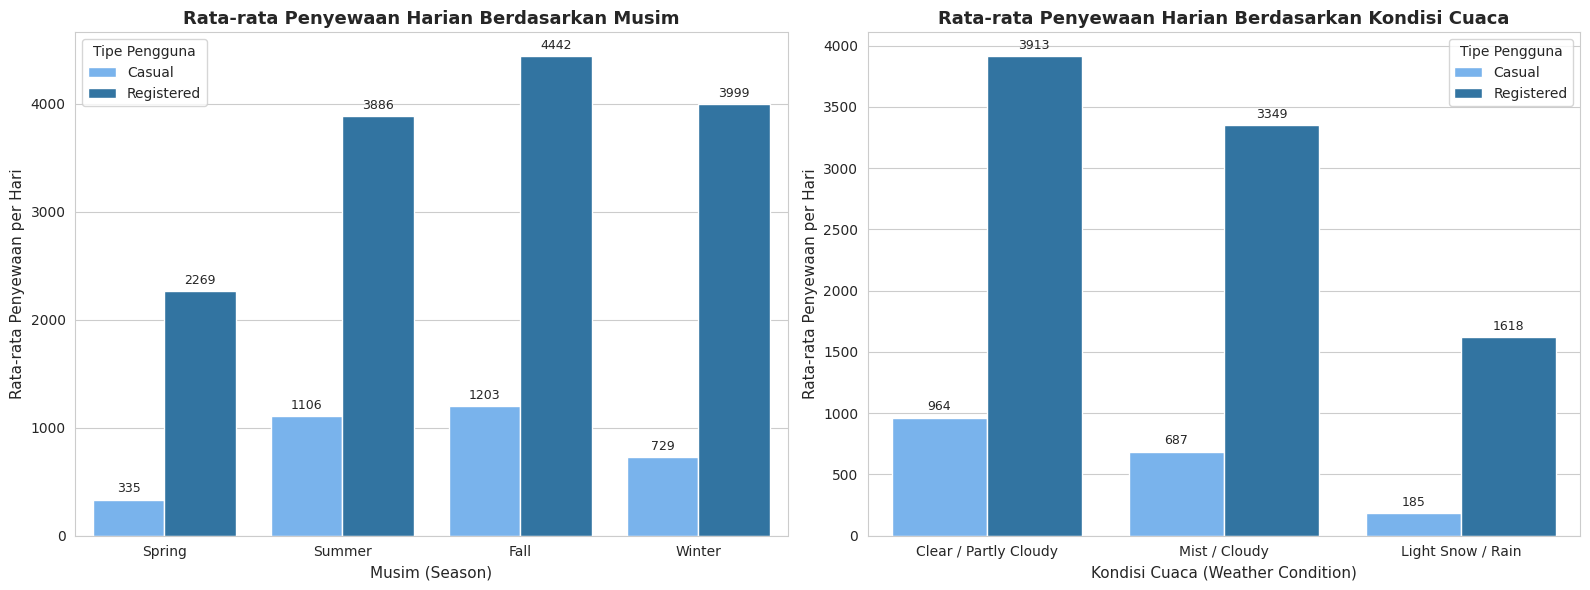

In [10]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Urutan musim secara kronologis
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_melt = day_df.melt(
    id_vars='season',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)

# Plot 1: Pengaruh Musim terhadap Tipe Pengguna
sns.barplot(
    data=season_melt,
    x='season',
    y='avg_rentals',
    hue='user_type',
    order=season_order,
    palette=['#66b3ff', '#1f77b4'],
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Rata-rata Penyewaan Harian Berdasarkan Musim', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Musim (Season)', fontsize=11)
axes[0].set_ylabel('Rata-rata Penyewaan per Hari', fontsize=11)
axes[0].legend(title='Tipe Pengguna', labels=['Casual', 'Registered'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

# Plot 2: Pengaruh Kondisi Cuaca terhadap Tipe Pengguna
weather_order = ['Clear / Partly Cloudy', 'Mist / Cloudy', 'Light Snow / Rain']
weather_melt = day_df.melt(
    id_vars='weather_condition',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)

sns.barplot(
    data=weather_melt,
    x='weather_condition',
    y='avg_rentals',
    hue='user_type',
    order=weather_order,
    palette=['#66b3ff', '#1f77b4'],
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Rata-rata Penyewaan Harian Berdasarkan Kondisi Cuaca', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Kondisi Cuaca (Weather Condition)', fontsize=11)
axes[1].set_ylabel('Rata-rata Penyewaan per Hari', fontsize=11)
axes[1].legend(title='Tipe Pengguna', labels=['Casual', 'Registered'])

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

**Insight Visualisasi Pertanyaan 1:**
* Pengguna terdaftar (*registered*) secara konsisten mendominasi penyewaan di seluruh musim maupun kondisi cuaca, dengan selisih 3 hingga 8 kali lipat dibandingkan pengguna kasual (*casual*).
* **Musim Fall (Gugur)** menjadi puncak aktivitas bagi kedua segmen pengguna (rata-rata **4.442** *registered* dan **1.203** *casual* per hari), sedangkan **Spring (Semi)** merupakan titik terendah (**2.269** *registered* dan **335** *casual* per hari)[cite: 23].
* Cuaca **Clear / Partly Cloudy** mendorong penyewaan tertinggi (**3.913** *registered* dan **964** *casual*), sedangkan cuaca **Light Snow / Rain** menekan minat pengguna kasual hingga turun lebih dari **80%** (menjadi **185**/hari) dibandingkan saat cuaca cerah[cite: 23].

### Pertanyaan 2 & Analisis Lanjutan: Pada rentang jam berapa terjadi lonjakan puncak penyewaan sepeda antara hari kerja dan akhir pekan/hari libur, serta bagaimana distribusi klaster waktunya?

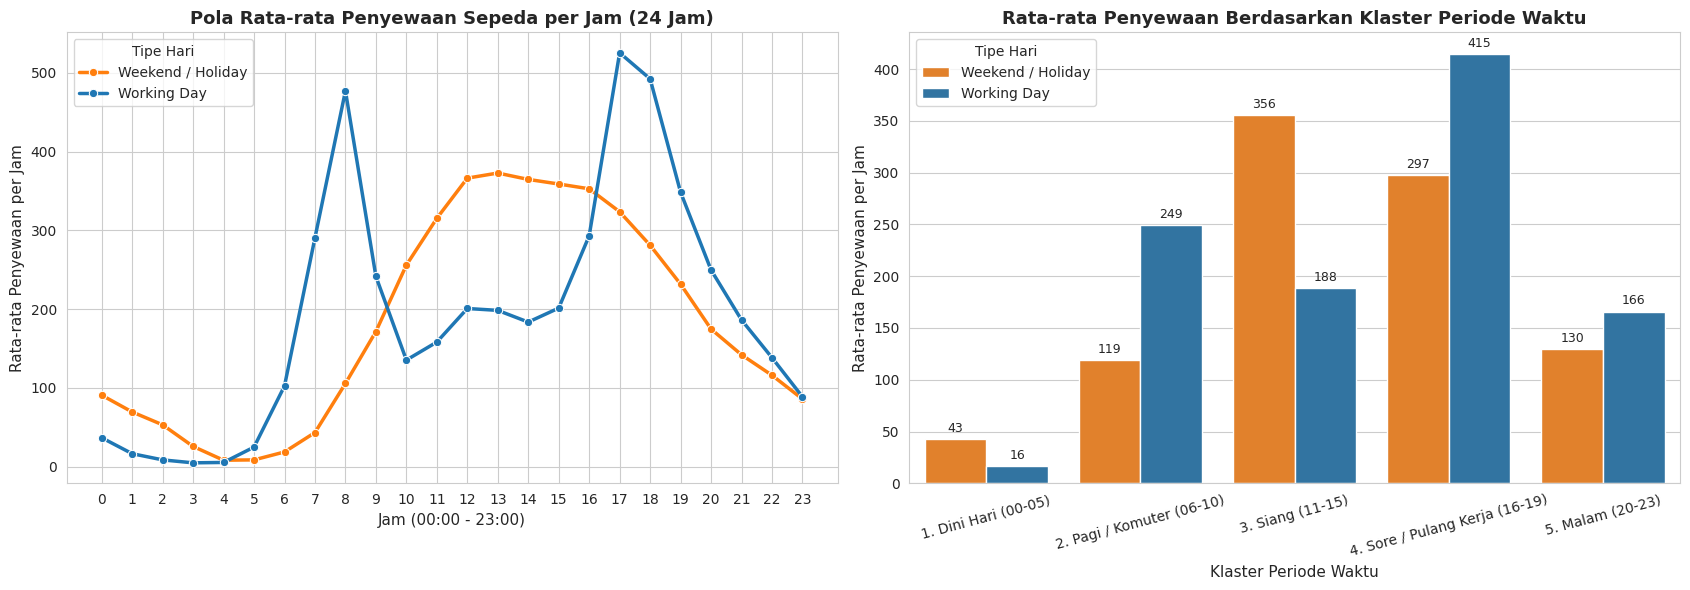

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Plot 1: Line Chart Pola Penyewaan 24 Jam (Working Day vs Weekend/Holiday)
sns.lineplot(
    data=hour_df,
    x='hour',
    y='total_count',
    hue='workingday_label',
    palette=['#ff7f0e', '#1f77b4'],
    marker='o',
    linewidth=2.5,
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Pola Rata-rata Penyewaan Sepeda per Jam (24 Jam)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Jam (00:00 - 23:00)', fontsize=11)
axes[0].set_ylabel('Rata-rata Penyewaan per Jam', fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].legend(title='Tipe Hari')

# Plot 2: Bar Chart Hasil Clustering Periode Waktu (Time Period)
period_order = [
    '1. Dini Hari (00-05)',
    '2. Pagi / Komuter (06-10)',
    '3. Siang (11-15)',
    '4. Sore / Pulang Kerja (16-19)',
    '5. Malam (20-23)'
]
sns.barplot(
    data=hour_df,
    x='time_period',
    y='total_count',
    hue='workingday_label',
    order=period_order,
    palette=['#ff7f0e', '#1f77b4'],
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Rata-rata Penyewaan Berdasarkan Klaster Periode Waktu', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Klaster Periode Waktu', fontsize=11)
axes[1].set_ylabel('Rata-rata Penyewaan per Jam', fontsize=11)
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(title='Tipe Hari')

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

**Insight Visualisasi Pertanyaan 2 & Analisis Lanjutan:**
* **Kontras Pola Harian (*Line Chart*):** Pada hari kerja (*Working Day*), grafik membentuk pola dua puncak (*bimodal*) yang tajam pada pukul **08:00** (jam berangkat kerja) dan pukul **17:00–18:00** (jam pulang kerja). Sebaliknya, pada akhir pekan/hari libur (*Weekend / Holiday*), penyewaan naik bertahap mulai pukul 09:00 dan membentuk satu puncak lebar (*unimodal*) pada rentang pukul **12:00–16:00**.
* **Perbandingan Klaster Periode Waktu (*Bar Chart*):** Pada hari kerja, klaster **Sore / Pulang Kerja (16–19)** memegang rata-rata tertinggi (**415** penyewaan/jam), diikuti **Pagi / Komuter (06–10)** (**249** penyewaan/jam). Sementara pada akhir pekan, klaster **Siang (11–15)** mendominasi dengan rata-rata **356** penyewaan/jam.
* **Window Operasional:** Klaster **Dini Hari (00–05)** mencatat aktivitas paling rendah di kedua kategori hari (**16**/jam pada hari kerja dan **43**/jam pada akhir pekan), sehingga sangat aman untuk jadwal perawatan armada dan *rebalancing* stok sepeda antarstasiun[cite: 24].

## Conclusion & Recommendation

### Kesimpulan
1. **Pengaruh Musim dan Kondisi Cuaca terhadap Penyewaan Sepeda (Pertanyaan 1):**
   * Musim gugur (**Fall**) merupakan periode dengan rata-rata penyewaan harian tertinggi (**5.644** sepeda/hari), sedangkan musim semi (**Spring**) menjadi yang terendah (**2.604** sepeda/hari).
   * Kondisi cuaca cerah/berawan sebagian (**Clear / Partly Cloudy**) menghasilkan rata-rata penyewaan tertinggi (**4.877** sepeda/hari). Ketika cuaca memburuk menjadi hujan/salju ringan (**Light Snow / Rain**), total penyewaan harian turun drastis sebesar **63%** (menjadi **1.803** sepeda/hari).
   * Segmen pengguna terdaftar (*registered*) menunjukkan loyalitas dan konsistensi penggunaan yang jauh lebih stabil dibandingkan pengguna kasual (*casual*), yang penyewaannya anjlok lebih dari **80%** saat cuaca buruk.

2. **Pola Jam Sibuk dan Klaster Waktu Operasional (Pertanyaan 2 & Analisis Lanjutan):**
   * **Hari Kerja (*Working Day*):** Penyewaan didominasi oleh aktivitas komuter (*registered* user sebesar 89%–95%) dengan dua puncak utama pada pukul **08:00** (**477**/jam) dan pukul **17:00–18:00** (**492–525**/jam), yang masuk ke dalam klaster **Pagi / Komuter (06–10)** dan **Sore / Pulang Kerja (16–19)**.
   * **Akhir Pekan / Hari Libur (*Weekend / Holiday*):** Penyewaan bersifat rekreasional dengan lonjakan pengguna *casual* hingga **35%–38%**, memuncak pada klaster **Siang (11–15)** dengan titik tertinggi pada pukul **13:00** (**373**/jam).

---

### Rekomendasi Bisnis (*Action Items*)
1. **Penjadwalan *Rebalancing* & *Maintenance* Berbasis Klaster Waktu:**
   * Lakukan perawatan armada dan distribusi ulang (*rebalancing*) stok sepeda secara menyeluruh pada klaster **Dini Hari (00:00–05:00)** saat permintaan berada di titik terendah (<45 penyewaan/jam).
   * Pada **hari kerja**, prioritaskan ketersediaan sepeda di area perumahan/stasiun transit sebelum pukul **07:30**, dan pindahkan stok ke area perkantoran sebelum pukul **16:30**. Pada **akhir pekan**, alihkan stok sepeda ke area taman, tempat wisata, dan pusat rekreasi sebelum pukul **11:00**.
2. **Strategi Promosi untuk Meningkatkan Pengguna Kasual & Musim Sepi:**
   * Luncurkan paket promo akhir pekan (*Weekend Pass*) atau diskon grup bagi pengguna *casual* pada siang hari (11:00–15:00) saat cuaca cerah di musim **Summer** dan **Fall** untuk memaksimalkan pendapatan.
   * Berikan insentif poin loyalitas atau diskon berlangganan pada musim **Spring** dan saat cuaca mendung (*Mist / Cloudy*) guna menjaga tingkat utilisasi armada tetap optimal di luar musim puncak.